# <p style="text-align:center;">UNIVERSIDADE ESTADUAL DE MONTES CLAROS - UNIMONTES</p>
# <p style="text-align:center;">ESPECIALIZAÇÃO EM INTELIGÊNCIA ARTIFICIAL</p>

# <p style="text-align:center;">Machine Learning</p>

# <p style="text-align:center;">Trabalho Prático 1 - Modelos Lineares</p>

**Resolução: Angelina de Meiras Ottoni | PPGMCS/Unimontes | IA-103 | 2026**

Os enunciados, a sequência das seções e os nomes de funções e variáveis do roteiro foram preservados. As implementações e análises foram inseridas nos espaços indicados; comentários adicionais estão identificados como notas da resolução.

O objetivo deste trabalho é consolidar os conhecimentos vistos nas aulas ao vivo das 4 primeiras semanas da disciplina. Para obter os resultados desejados é importante trabalhar na implementação de todos os métodos vistos: Regressão Linear Simples, Regressão Linear com Múltiplas variáveis, Feature Scaling e Feature Engineering, Regressão Polinomial e Regressão Logística, Regularização e Seleção de Modelos.

Seguem os pacotes necessários às implementações:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
%matplotlib inline

**Notas da resolução - execução e ajustes técnicos**

Execução em Python 3.12, com os quatro arquivos de dados na mesma pasta. As células devem ser executadas em ordem. Foram preservados, entre outros, `X`, `y`, `theta`, `alpha`, `iterations`, `J`, `J_history`, `grad`, `dataset_novo`, `cost` e `regularization`.

- `J_history` contém um custo por atualização, como solicitado. O vetor inicial não ocupa uma posição adicional no histórico.
- A normalização preserva a coluna de intercepto; utiliza desvio padrão populacional e divisor 1 para atributos constantes.
- A sigmoide e o custo logístico usam expressões matematicamente equivalentes e numericamente estáveis, evitando overflow e logaritmo de zero.
- A fórmula do custo regularizado e seu gradiente no roteiro apresentam diferença de fator. A convenção adotada é explicada junto à implementação.
- Os gráficos foram mantidos nas saídas do notebook, sem dependência de imagens externas. As duas referências a imagens ausentes no material são sinalizadas nos respectivos locais.
- `gtol=1e-5` foi explicitado no CG; o ajuste regularizado utiliza BFGS, permitido pela chamada genérica a `minimize` no roteiro. O estado de convergência é verificado.

Alterações de apresentação nos gráficos limitam-se a títulos, rótulos e legendas. Os nomes dos quatro arquivos de dados foram mantidos para compatibilidade com o roteiro.

## 1 - Regressão Linear Simples
Considere a resolução do problema de uma empresa de Food Truck que pretende contratar um modelo para predição de lucro. Para isso, você deverá implementar o algoritmo de Regressão Linear. Essa empresa já possui diversas filiais e 
pretende iniciar uma pesquisa de mercado para abertura de novas unidades. Para obter um bom modelo preditivo serão utilizados dados relativos às franquias já existentes, estes dados contêm o lucro e a população das cidades.
O arquivo food_truck.txt contém os dados que deverão ser utilizados. Cada linha do arquivo é uma cidade; a primeira coluna contem a população e a segunda o lucro, da cidade correspondente.

Visualização das primeiras linhas da base de dados:

In [2]:
# Carregando os dados
data = pd.read_csv('food_truck.txt', header=None, names=['População', 'Lucro'])

# Inicializando algumas variáveis
m = len(data) # Número de amostras de treinamento
X = np.append(np.ones((m, 1)), np.array(data["População"]).reshape((m,1)), axis=1) # Adicione x0, um vetor de 1's, em X.
y = np.array(data["Lucro"]).reshape(m, 1)

data.head()

,População,Lucro
0,6.1101,17.5920
1,5.5277,9.1302
2,8.5186,13.6620
3,7.0032,11.8540
4,5.8598,6.8233


### 1.1 - Plotando os Dados

Plotar os dados nos dá um idéia de como é a distribuição espacial dos dados:

Text(0.5, 1.0, 'Relação entre Lucro e População')

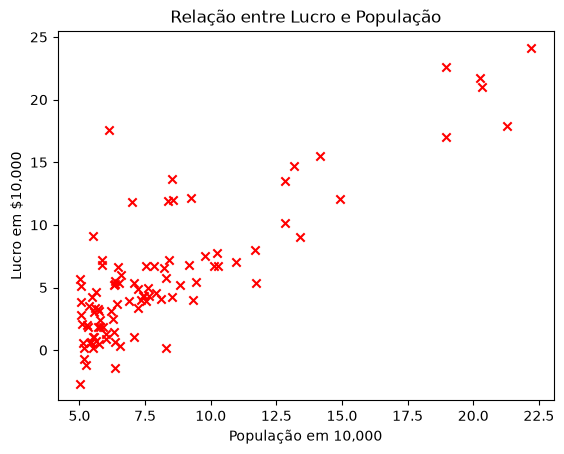

In [3]:
plt.scatter(data['População'], data['Lucro'], marker='x', c='red')
plt.xlabel('População em 10,000')
plt.ylabel('Lucro em $10,000')
plt.title('Relação entre Lucro e População')

### 1.2 - Implementação do Gradiente Descendente

Nesta seção você deverá implementar a versão Batch do algoritmo Gradiente Descendente para encontrar os parâmetros $\vec{\theta}$ do modelo de regressão Linear: $y= h_\theta(x)= \theta_0 + \theta_1x$. Inicialilze $\vec{\theta}$ com valores zero e defina a taxa de aprendizado $\alpha=0.01$. Em seguida, implemente o código faltante para a função de custo $$J(\theta) = \frac{1}{2m} \displaystyle\sum_{i = 0}^{m}(h_θ(x^{(i)}) - y^{(i)})^2$$ completando o código a seguir:

In [4]:
def funcao_custo(X, y, theta):
    """Custo quadrático médio, com o fator 1/2 do roteiro."""
    erro = X @ np.asarray(theta).reshape(-1, 1) - np.asarray(y).reshape(-1, 1)
    J = float(np.sum(erro ** 2) / (2 * len(y)))
    return J

Ao testar esta função como o vetor $\vec{\theta} = \begin{bmatrix}0 & 0\end{bmatrix}$, $J(\theta)$ deve retornar um valor de aproximadamente  32.07.

In [5]:
theta_inicial = np.zeros((2,1))
print(funcao_custo(X, y, theta_inicial))

32.072733877455676


Após testar a função de custo e garantir que ela está funcionando corretamente, você deve implementar o algoritmo do Gradiente Descendente, cuja definição formal é: 
$ \\[0.3cm] repeat \{ \\ \enspace \qquad \qquad \theta_j := \theta_j - \alpha \frac{1}{m}\displaystyle\sum_{i = 1}^{m}(h_\theta(x^{(i)})-y^{(i)})x_j^{(i)}\\\} \\$ 

Para implementá-lo, complete a função a seguir:

In [6]:
def gradient_descent(X, y, theta, alpha, iterations):
    """Gradiente batch; J_history registra o custo após cada atualização."""
    theta = np.array(theta, dtype=float, copy=True).reshape(-1, 1)
    y = np.asarray(y).reshape(-1, 1)
    J_history = []
    for _ in range(iterations):
        grad = X.T @ (X @ theta - y) / len(y)
        theta = theta - alpha * grad
        J_history.append(funcao_custo(X, y, theta))
    return theta, J_history

Após a convergência, o Gradiente Descendente deve produzir aproximadamente o seguinte vetor de parâmetros: $\vec{\theta} = \begin{bmatrix}-3.6303\\1.1664\end{bmatrix}$

**Nota da resolução:** os parâmetros aproximados apresentados acima no roteiro não são o ponto ótimo exato da base. O número de atualizações influencia o resultado. A comparação com mínimos quadrados e com 15.000 atualizações, apresentada adiante, permite conferir a convergência sem forçar o resultado a coincidir com essa referência intermediária.

Agora, altere os parâmetros do Algoritmo para analisar o seu comportamento, e verifique as mudanças na curva do erro ($J(\theta)$ a cada iteração) e no vetor $\vec{\theta}$. Exemplo de alterações:

In [7]:
alpha = 0.01
iterations = 2000

theta, J_history = gradient_descent(X, y, theta_inicial, alpha, iterations)
theta

array([[-3.78806857],
       [ 1.18221277]])

Text(0, 0.5, 'Custo J')

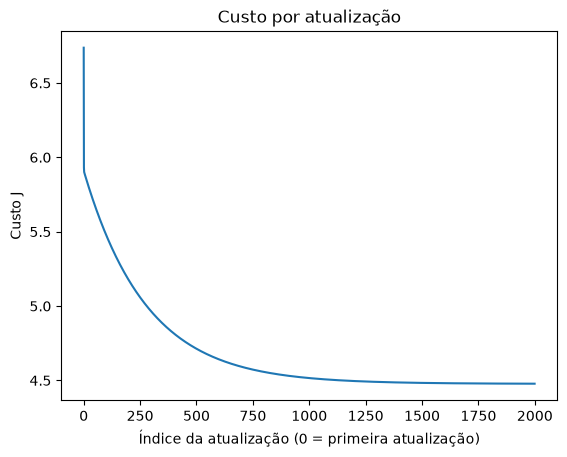

In [8]:
#Verificando a curva de erro a cada iteração
plt.plot(J_history)
plt.title('Custo por atualização')
plt.xlabel('Índice da atualização (0 = primeira atualização)')
plt.ylabel('Custo J')

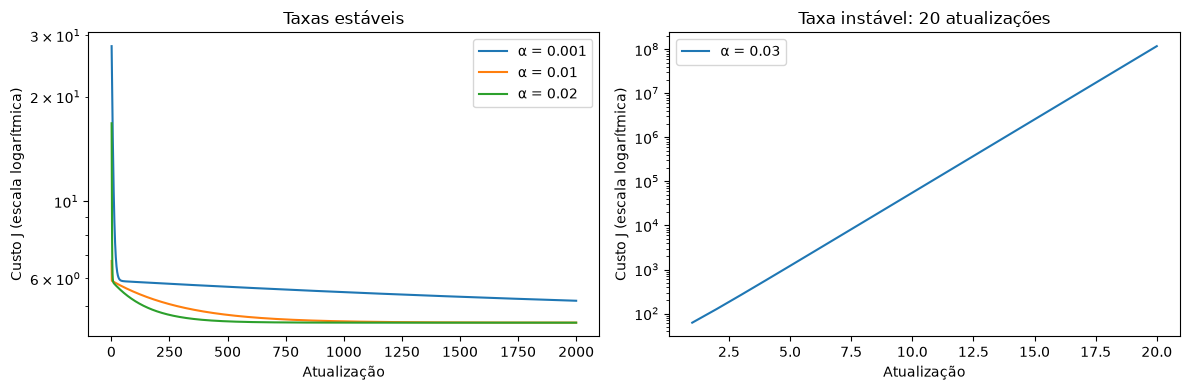

,alpha,iteracoes,theta_0,theta_1,custo_final
0,0.001,2000,-1.123690,0.914547,5.176563e+00
1,0.010,2000,-3.788069,1.182213,4.478028e+00
2,0.020,2000,-3.892881,1.192742,4.476972e+00
3,0.030,20,-169.573160,-1683.844568,1.178589e+08


Limite de estabilidade para alpha: 0.024324


,iteracoes,theta_0,theta_1,custo_final
0,100,-0.576556,0.859582,5.479976
1,500,-2.282867,1.030999,4.713810
2,2000,-3.788069,1.182213,4.478028
3,15000,-3.895781,1.193034,4.476971


Referência por mínimos quadrados: [-3.89578088  1.19303364]


In [9]:
# Experimentos adicionais solicitados: efeito de alpha e de iterations.
# As variáveis do ajuste principal theta e J_history não são sobrescritas.
alpha_limit = 2 / np.linalg.eigvalsh(X.T @ X / len(y)).max()
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for alpha_test in [.001, .01, .02, .03]:
    iterations_test = 20 if alpha_test >= alpha_limit else 2000
    theta_test, J_history_test = gradient_descent(X, y, theta_inicial, alpha_test, iterations_test)
    rows.append({'alpha': alpha_test, 'iteracoes': iterations_test,
                 'theta_0': theta_test[0, 0], 'theta_1': theta_test[1, 0],
                 'custo_final': J_history_test[-1]})
    ax = axes[1] if alpha_test >= alpha_limit else axes[0]
    ax.semilogy(np.arange(1, len(J_history_test)+1), J_history_test, label=f'α = {alpha_test}')
for ax, title in zip(axes, ['Taxas estáveis', 'Taxa instável: 20 atualizações']):
    ax.set(xlabel='Atualização', ylabel='Custo J (escala logarítmica)', title=title)
    ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))
print(f'Limite de estabilidade para alpha: {alpha_limit:.6f}')
theta_reference = np.linalg.lstsq(X, y, rcond=None)[0]
rows = []
for iterations_test in [100, 500, 2000, 15000]:
    theta_test, J_history_test = gradient_descent(X, y, theta_inicial, .01, iterations_test)
    rows.append({'iteracoes': iterations_test, 'theta_0': theta_test[0, 0],
                 'theta_1': theta_test[1, 0], 'custo_final': J_history_test[-1]})
display(pd.DataFrame(rows))
print('Referência por mínimos quadrados:', theta_reference.ravel())
assert np.allclose(theta_test, theta_reference, atol=1e-7)

Verifique a reta obtida após o aprendizado dos parâmetros, utilizando o script a seguir:

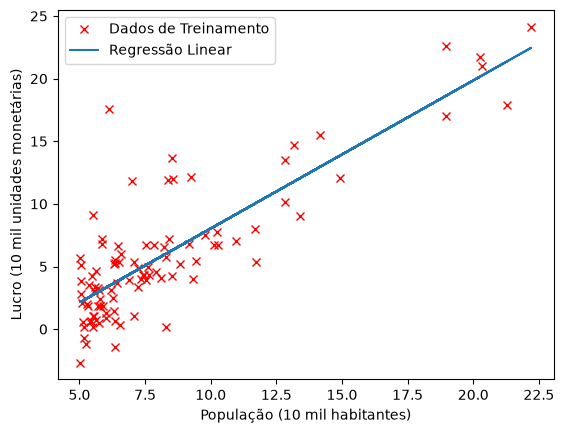

In [10]:
plt.plot(X[:,1], y, 'rx', label='Dados de Treinamento')
plt.plot(X[:,1], X.dot(theta), label='Regressão Linear')
plt.xlabel('População (10 mil habitantes)')
plt.ylabel('Lucro (10 mil unidades monetárias)')
plt.legend()

Para finalizar esta parte do trabalho, faça uma predição usando o modelo aprendido pelo algoritmo. Considere 2 cidades com populações de 35000 e 100000 habitantes respectivamente, qual o lucro predito para estas cidades????

In [11]:
# População e lucro estão expressos em unidades de 10.000.
populacoes = np.array([35000, 100000])
X_novo = np.column_stack([np.ones(2), populacoes / 10000])
lucros = (X_novo @ theta).ravel() * 10000
display(pd.DataFrame({'População': populacoes, 'Lucro previsto': lucros}))
assert np.isclose(funcao_custo(X, y, theta_inicial), 32.072733877455676)
assert len(J_history) == iterations
assert np.all(np.diff(J_history) <= 1e-10)

,População,Lucro previsto
0,35000,3496.761389
1,100000,80340.591749


**Análise da resolução:** com α = 0,01 e 2.000 atualizações, os parâmetros foram -3,788069 e 1,182213, e o custo final foi 4,478028. Os lucros previstos foram 3.496,76 e 80.340,59 unidades monetárias. A previsão para 35 mil habitantes extrapola o mínimo observado de aproximadamente 50 mil. A taxa 0,001 reduz o erro mais lentamente; 0,03 produz divergência e foi limitada a 20 atualizações para evitar overflow. Com 15.000 atualizações, os parâmetros aproximam-se da referência de mínimos quadrados (-3,895781; 1,193034). A associação entre população e lucro não demonstra causalidade.

## 2 - Regressão Linear Múltipla

Agora você deverá implementar um algoritmo para Regressão Linear com Múltiplas Variáveis para predição do preço de venda de imóveis. Este problema é o mesmo usado como exemplo de tarefa de regressão nas aulas ao vivo das primeiras semanas da disciplina. O arquivo imoveis.txt contém as informações dos imóveis. A coluna 1 corresponde ao tamanho do imóvel (em pés quadrados), na coluna 2 está a quantidade de quartos do imóvel, e a terceira coluna corresponde ao preço do imóvel.
Obs: 1 pé corresponde a 0.3048 metros.

O código a seguir mostra as primeiras linhas do arquivo imoveis.txt:

In [12]:
# Carregando os dados para a variável (data)
data = pd.read_csv("imoveis.txt", header = None, names=["Size", "Bedrooms","Price"])
m = len(data)

# Inicializando X, y e o vetor de parâmetros (theta)
x0 = np.ones(m)
size = np.array((data["Size"]))
bedrooms = np.array((data["Bedrooms"]))
X = np.array([x0, size, bedrooms]).T
y = np.array(data["Price"]).reshape(len(data.index), 1)
theta_init = np.zeros((3,1))

data.head()

,Size,Bedrooms,Price
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


### 2.1 Normalização das Features

Quando as features tem grandes diferenças com relação à ordem de magnitude, algumas delas podem ter maior influência na direção de busca do gradiente, dominando o processo de busca em determinadas direções. Analisando-se a base de dados, podemos verificar que a coluna relativa ao tamanho dos imóveis tem valores aproximadamente 1000 vezes maiores que os valores da coluna que contém a quantidade de quartos. Desta forma, para aumentar a velocidade de convergência do algoritmo Gradiente Descendente, implemente a normalização das features (Feature Scaling) atualizando o valor de cada coluna de dados usando a seguinte formula: $x := \frac{x - \mu}{\sigma}$, onde $\mu$ é a média e $\sigma$ é o desvio padrão. Complete a função a seguir para realizar a normalização. A função recebe a matriz de dados X como parâmetro e retorna o valor atualizado de X e os valores calculados de $\mu$ e $\sigma$.


In [13]:
# Função para realização da normalização
def normalize(X):
    """Padroniza os atributos; preserva a primeira coluna de uns (intercepto)."""
    X = np.array(X, dtype=float, copy=True)
    mu = X.mean(axis=0)
    sigma = X.std(axis=0, ddof=0)
    sigma = np.where(sigma == 0, 1., sigma)
    mu[0], sigma[0] = 0., 1.
    X = (X - mu) / sigma
    return X, mu, sigma

X, mu, sigma = normalize(X)
assert np.allclose(X[:, 0], 1)
assert np.allclose(X[:, 1:].mean(axis=0), 0, atol=1e-14)
assert np.allclose(X[:, 1:].std(axis=0), 1)
X[0:5]

array([[ 1.        ,  0.13141542, -0.22609337],
       [ 1.        , -0.5096407 , -0.22609337],
       [ 1.        ,  0.5079087 , -0.22609337],
       [ 1.        , -0.74367706, -1.5543919 ],
       [ 1.        ,  1.27107075,  1.10220517]])

### Observação importante sobre a normalização:
É importante armazenar os valores de $\mu$ e $\sigma$ calculados para cada variável, pois quando for testar o modelo aprendido para prever o valor de um novo imóvel, você deverá usar os valores armazenados (obtidos através dos dados de treinamento) para normalizar as features deste novo imóvel, antes de testar o modelo sobre o novo dado [area, qtde_quartos].

### 2.2 - Gradiente Descendente

Implemente o algoritmo Gradiente Descendente para realizar a regressão com múltiplas variáveis. Garanta que sua implementação seja na forma vetorial e genérica (suportando qualquer quantidade de features). Tome a função a seguir como base para sua implementação:

In [14]:
def gradient_descent_multi(X, y, theta, alpha, iterations):
    """Gradiente batch vetorizado, válido para qualquer número de atributos."""
    theta = np.array(theta, dtype=float, copy=True).reshape(-1, 1)
    y = np.asarray(y).reshape(-1, 1)
    J_history = []
    for _ in range(iterations):
        grad = X.T @ (X @ theta - y) / len(y)
        theta = theta - alpha * grad
        J_history.append(funcao_custo(X, y, theta))
    return theta, J_history

alpha = 0.01
iterations = 2000
initial_theta = np.zeros((3,1))
theta, J_history = gradient_descent_multi(X, y, initial_theta, alpha, iterations)
theta

array([[340412.65894002],
       [109439.22578243],
       [ -6569.78416695]])

Faça a análise da curva de erro para cada iteração do algoritmo, gerando um gráfico similar àquele obtido para regressão linear simples

Text(0, 0.5, 'custo')

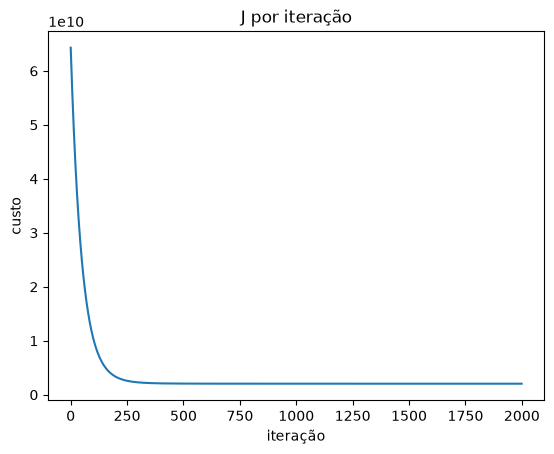

In [15]:
plt.plot(J_history)
plt.title('J por iteração')
plt.xlabel('iteração')
plt.ylabel('custo')

Para finalizar esta parte do trabalho, faça uma predição usando o modelo obtido pelo algoritmo. Considere um imóvel com 1650 pés quadrados e 3 quartos. Qual o preço predito para este imóvel?

In [16]:
novo_imovel = np.array([[1., 1650., 3.]])
novo_imovel = (novo_imovel - mu) / sigma
preco = (novo_imovel @ theta).item()
theta_referencia = np.linalg.lstsq(X, y, rcond=None)[0]
preco_referencia = (novo_imovel @ theta_referencia).item()
print(f'Preço previsto: {preco:,.2f} unidades monetárias')
print(f'Referência por mínimos quadrados: {preco_referencia:,.2f}')
assert np.isclose(preco, preco_referencia, rtol=1e-4)
assert np.all(np.diff(J_history) <= 1e-4)
assert len(J_history) == iterations

Preço previsto: 293,083.35 unidades monetárias
Referência por mínimos quadrados: 293,081.46


**Análise da resolução:** a padronização facilita a convergência quando os atributos têm escalas diferentes. As estatísticas calculadas na base foram reutilizadas na nova observação. Para 1.650 pés² e três quartos, o preço estimado foi 293.083,35 unidades monetárias, próximo dos 293.081,46 de mínimos quadrados. O custo diminui ao longo das atualizações. O coeficiente de quartos descreve sua associação com preço mantendo área constante; não caracteriza efeito causal. A avaliação foi feita na própria base, sem estimar generalização.

## 3 - Regressão Logística

O objetivo da Regressão Logística é predizer a que categoria(classe) uma certa amostra pertence. Considerando-se classificação binária, existem apenas 2 possíveis classes: $y \in \{0,1\}$.

Nesta Seção, com o objetivo de fixar o conteúdo, você deverá implementar o algoritmo de Regressão Logística e aplicá-lo a uma base de dados para predição de aprovação de um estudante com base nos resultados de 2 avaliações realizadas por ele. A base de dados(arquivo estudantes.txt) contem dados históricos referentes a avaliações passadas, onde as colunas da base são: Avaliação 1, Avaliação 2 e resultado(aprovado ou reprovado).

### 3.1 - Visualização da Base de Dados

O código a seguir mostra as primeiras linhas do arquivo estudantes.txt:

In [17]:
# Carregando os dados para a variável "data"
data = pd.read_csv("estudantes.txt", header = None, names = ["Avaliacao 1", "Avaliacao 2", "Aprovado"])

# Inicializando Variáveis
m = len(data["Aprovado"])
x0 = np.ones(m)
avaliacao_1 = np.array((data["Avaliacao 1"]))
avaliacao_2 = np.array((data["Avaliacao 2"]))
X = np.array([x0, avaliacao_1, avaliacao_2]).T
y = np.array(data["Aprovado"]).reshape((m,1))
m, n = X.shape

print("Matriz X:\n",X[:5])
print("\n\nDados brutos: ")
data.head()

Matriz X:
 [[ 1.         34.62365962 78.02469282]
 [ 1.         30.28671077 43.89499752]
 [ 1.         35.84740877 72.90219803]
 [ 1.         60.18259939 86.3085521 ]
 [ 1.         79.03273605 75.34437644]]


Dados brutos: 


,Avaliacao 1,Avaliacao 2,Aprovado
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1


Plotando os dados - As cores diferenciam aprovados e reprovados:

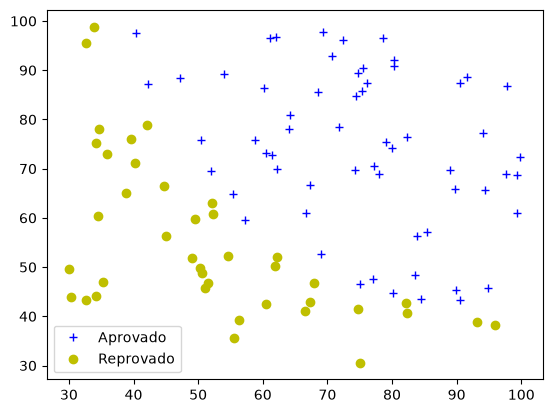

In [18]:
# Encontrando os indíces das classes positiva(Aprovado) e negativa(reprovado)
pos = np.where(y==1)[0]
neg = np.where(y==0)[0]

# Plotando as amostras
plt.plot(X[pos, 1], X[pos, 2], 'b+', label='Aprovado')
plt.plot(X[neg, 1], X[neg, 2], 'yo', label='Reprovado')
plt.legend()
plt.show()

### 3.2 - Implementação do Algoritmo de Aprendizado

A primeira etapa para implementação do algoritmo para regressão logística é a definição da função sigmoid. Ao utilizar esta função, a hipótese passa a ter a seguinte forma: $h_\theta(x) = g(z) = g(\theta^Tx) = \frac{1}{1+ e^{-z}} = \frac{1}{1+ e^{-\theta^Tx}}$.

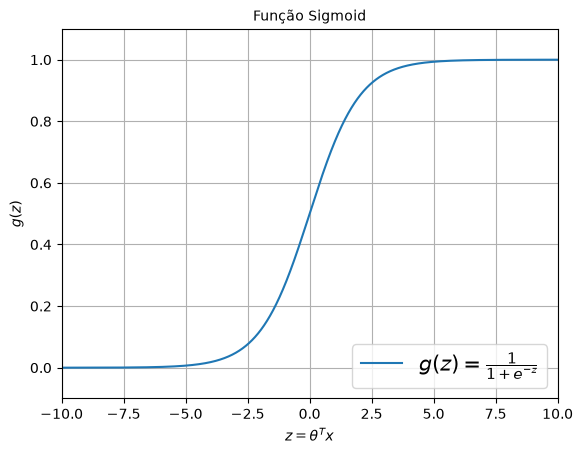

In [19]:
# Forma estável e equivalente a 1/(1+exp(-z)); evita overflow.
sigmoid = lambda z: np.exp(-np.logaddexp(0, -np.asarray(z, dtype=float)))

def plot_sigmoid():
  plt.grid()
  plt.xlim([-10.0, 10.0])
  plt.ylim([-0.1, 1.1])
  x = np.arange(-10, 10, 0.001)
  plt.xlabel(r'$z = \theta^Tx$', size=10)
  plt.ylabel('$g(z)$', size=10)
  plt.title('Função Sigmoid', size=10)
  plt.plot(x, sigmoid(x), label=r'$g(z)= \frac{1}{1+e^{-z}}$')
  plt.legend(loc='lower right', fontsize=15)

plot_sigmoid()

Teste a função sigmóide antes de partir para a implementação da função de custo e do gradiente. Ela deve retornar $\frac{1}{2}$ caso você passe o valor $0$ como parâmetro, retornar $1$ caso você passe um valor grande positivo e retornar $0$ caso você passe um valor grande e negativo. 

In [20]:
for z in [-1000., -10., 0., 10., 1000.]:
    print(f'g({z:g}) = {sigmoid(z):.6f}')
assert sigmoid(0) == .5
assert sigmoid(1000) == 1 and sigmoid(-1000) == 0

g(-1000) = 0.000000
g(-10) = 0.000045
g(0) = 0.500000
g(10) = 0.999955
g(1000) = 1.000000


Implemente agora a função de custo para regressão logística. Lembre-se que ela tem um formato diferente da regressão linear: $$J(\theta) = - \begin{bmatrix}\frac{1}{m}\displaystyle\sum_{i=1}^{m}-y^{(i)}\log h(x^{(i)}-(1-y^{(i)})\log(1-h_\theta(x^{(i)}))\end{bmatrix}$$

Implemente a função de custo utilizando vetorização: $$J(\theta) = \frac{1}{m} ⋅(−y^T \log(h)−(1−y)^T \log(1−h))$$

Você pode definir a função de custo completando a função abaixo:

In [21]:
def compute_cost(theta, X, y):
    """Entropia cruzada calculada sem logaritmos de probabilidades extremas."""
    z = X @ np.asarray(theta).ravel()
    y = np.asarray(y).ravel()
    return float(np.mean(np.logaddexp(0, z) - y * z))

Agora, você deve implementar um função para calcular o vetor gradiente $\nabla(\theta)$, contendo as derivadas parciais da função de custo com relação a cada parâmetro $\frac{\delta}{\delta\theta_J}$:
$$\frac{\delta}{\delta\theta_J} = \frac{1}{m}\displaystyle\sum_{i = 1}^{m} \begin{bmatrix}(h_\theta(x^{(i)}) - y^{(i)}\end{bmatrix}x_j^{(i)}$$
Perceba que esta é uma etapa interemediária que utilizamos para implementar o algoritmo do Gradiente Descendente. Entretanto, desta vez é importante implementar esta função intermediária de forma genérica, uma vez que o vetor $\nabla(\theta)$ pode ser utilizado em outros algoritmos de aprendizado baseados em direção de busca. Complete a função a seguir para computar o vetor gradiente:

In [22]:
def compute_gradient(theta, X, y):
    y = np.asarray(y).ravel()
    grad = X.T @ (sigmoid(X @ np.asarray(theta).ravel()) - y) / len(y)
    return grad

Teste a função de custo e o gradiente. Inicializando $\vec{\theta}$ com zeros, você deve obter $J(\theta) \approx 0.693$ e $\frac{\delta}{\delta\theta_J} \approx \begin{bmatrix}-0.1000 & -12.0092 & -11.2628 \end{bmatrix}$

In [23]:
initial_theta = np.zeros(n)
print('Cost: \n{}\n'.format(compute_cost(initial_theta, X, y)))
print('Gradient: \n{}'.format(compute_gradient(initial_theta, X, y)))

assert np.isclose(compute_cost(initial_theta, X, y), np.log(2))
assert np.allclose(compute_gradient(initial_theta, X, y), [-.1, -12.00921659, -11.26284221])
from scipy.optimize import check_grad
erro_gradiente = check_grad(compute_cost, compute_gradient,
                           np.array([-.2, .01, -.01]), X, y)
print(f'Erro absoluto da checagem do gradiente: {erro_gradiente:.2e}')
assert erro_gradiente < 1e-3


Cost: 
0.6931471805599453

Gradient: 
[ -0.1        -12.00921659 -11.26284221]


Erro absoluto da checagem do gradiente: 1.21e-05


Diferentemente de como fizemos nas partes iniciais deste trabalho, onde usamos o algoritmo Gradiente Descendente para aprender os parâmetros $\vec{\theta}$, utilizaremos agora um outro algoritmo de aprendizado, o Gradiente Conjugado. A implementação deste algoritmo não é escopo deste trabalho, caso tenha interesse em estudar mais sobre ele, pode pesquisar  [aqui (em inglês)](https://en.wikipedia.org/wiki/Conjugate_gradient_method). Para utilizá-lo, vamos precisar da biblioteca de otimização scipy.optimize, que fornece a função minimize para realizarmos o processo de minimização de $J(\theta)$. Para utilizá-la temos que fornecer nossa função de custo (compute_cost), nossa função para obtenção de $\nabla(\theta)$(compute_gradient), e os valores iniciais de $\vec(\theta)$.

Antes de utilizar o algoritmo, leia a documentação da função ([minimize](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)) e faça um pequeno resumo(cerca 10 linhas) sobre o funcionamento e principais parâmetros permitidos na função. 

OBS: Caso você tenha dificuldades de utilizar o método de gradientes conjugados ou a função minimize, pode-se utilizar o Gradiente Descendente, de maneira similar à implementação feita nas seções anteriores.

#### Resuma a função minimize aqui ...

`minimize` busca parâmetros que reduzam uma função escalar de custo.  
`fun` recebe a função de custo, avaliada para um vetor de parâmetros.  
`x0` define o vetor inicial, preenchido com zeros neste exercício.  
`args` transporta os dados fixos, como X e y, até as funções.  
`method='CG'` seleciona o método de gradientes conjugados não linear.  
`jac` recebe a função responsável pelo gradiente analítico.  
`tol` controla a tolerância geral; `gtol` permite ajuste específico do método.  
`options` permite configurar parâmetros como `maxiter` e `disp`.  
`bounds` e `constraints` dependem do método e não são utilizados com CG neste ajuste.  
O retorno inclui `x`, `fun`, `success` e `message`, utilizados para conferir o resultado.

Fonte: [documentação oficial do SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html), consultada em 21/10/2026.

In [24]:
from scipy.optimize import minimize
result = minimize(compute_cost, initial_theta, args = (X, y),
                   method = 'CG', jac = compute_gradient, 
                   options = {"maxiter": 400, "disp" : 1, "gtol": 1e-5})
theta = result.x
print('O gradiente Conjugado encontrou os seguintes valores para theta: {}'.format(theta))
assert result.success, result.message
print("Custo final:", result.fun)

Optimization terminated successfully.
         Current function value: 0.203498
         Iterations: 107
         Function evaluations: 246
         Gradient evaluations: 246
O gradiente Conjugado encontrou os seguintes valores para theta: [-25.1672507    0.20627904   0.20151948]
Custo final: 0.20349770679498222


### 3.3 - Superfície de Decisão

A superfície de decisão será uma linha no caso desta base bidimensional, que separa as áreas onde o valor predito é y=1 e y=0.

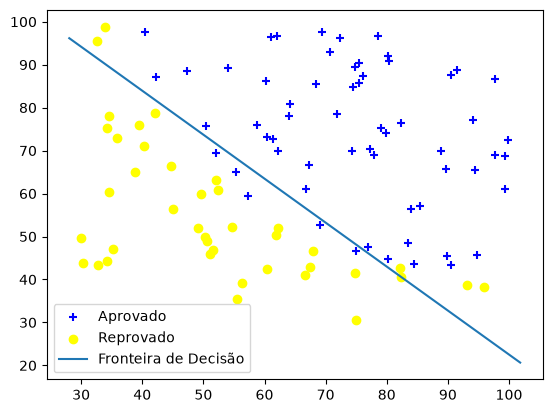

In [25]:
# Encontra os indíces de amostras positivas e negativas
pos = np.where(y==1)[0]
neg = np.where(y==0)[0]

# Plota as amostras
plt.scatter(X[pos, 1], X[pos, 2], c='blue', marker='+', label='Aprovado')
plt.scatter(X[neg, 1], X[neg, 2], c='yellow', marker='o', label='Reprovado')
plt.legend()

#Não use este vetor theta a seguir
#Este é o vetor ótimo que a sua implementação deve encontrar
#theta = np.array([-25.15522426,0.20618292,0.20142209])

# Plota a fronteira de decisão
plot_x = np.array([min(X[:,1])-2,  max(X[:,1])+2])
plot_y = (-1./theta[2]) * ((theta[1] * (plot_x) + theta[0]))

plt.plot(plot_x, plot_y, label='Fronteira de Decisão')

# Legend, specific for the exercise
plt.legend()

Após visualizar a fronteira de decisão, teste uma nova entrada para avaliar a probabilidade do candidato ser aprovado. Considerando-se um candidato com notas próximas de 45 e 85, na primeira e segunda avaliação, respectivamente, a probabiliade deve estar próxima de 0.8.

In [26]:
probabilidade = sigmoid(np.array([1., 45., 85.]) @ theta).item()
print(f'Probabilidade de aprovação para notas 45 e 85: {probabilidade:.2%}')
assert .77 < probabilidade < .79

Probabilidade de aprovação para notas 45 e 85: 77.63%


Agora, para predizer a quantidade de acertos que o seu modelo aprendido está obtendo nos dados de treinamento, complete a implementação das funções "predict" e "accuracy". A função "predict" retorna $1$(Aprovado) ou $0$(Reprovado) para todas as amostras da base de dados, enquanto a função "accuracy" utiliza a função "predict" para contabilizar a quantidade de acertos. Para este nosso conjunto de dados, é esperado que o modelo tenha cerca de 89% de acerto. 

Observe que em uma aplicação real, deveriamos considerar dividir a base de dados em dois conjuntos (treinamento e teste), onde o modelo deveria ser avaliado em dados que não foram vistos por ele durante o processo de treinamento.

In [27]:
def predict(X, theta):
    predicts = (sigmoid(X @ np.asarray(theta).ravel()) >= .5).astype(int)
    return predicts

def accuracy(X, y, theta):
    y_hat = predict(X, theta)
    acertos = float(np.mean(y_hat == np.asarray(y).ravel()))
    return acertos

In [28]:
acertos = accuracy(X, y, theta)
print(f'Acurácia no treinamento: {acertos:.2%}')
assert np.isclose(acertos, .89)
assert accuracy(X, y.ravel(), theta) == acertos

Acurácia no treinamento: 89.00%


**Análise da resolução:** para notas 45 e 85, a probabilidade foi 77,63%, com classificação positiva no limiar 0,5. A acurácia foi 89% e o custo final 0,203498. Esses valores descrevem ajuste nos 100 estudantes usados no treinamento. Não constituem avaliação independente em novos estudantes nem demonstram calibração das probabilidades.

## 4 - Regularização

Regularização é um dos possíveis mecanismos que utilizamos para evitar o problema de overfitting. Lembrando que overfitting quer dizer que nosso modelo se ajustou de mais aos nossos dados de treinamento e aprendendo inclusive o ruído inerente ao processo de amostragem. Por outro lado, se utilizarmos a regularização de maneira incorreta podemos ter o problema de underfitting, que é gerado quando nosso modelo não tem capacidade suficiente de aproximar os dados, devido a um treinamento ineficiente, poucos parâmetros ou mapeamento de features feito de forma incorreta.

O problema a ser resolvido agora consiste na predição de se os microchips de uma usina de fabricação passam na garantia de qualidade (QA). Durante o processo de QA, cada microchip passa por vários testes visando assegurar o correto funcionamento.
A base de dados que utilizaremos consiste no resultado de 2 testes realizados, e os correspondentes resultados para alguns microchips. Desta forma, construiremos um modelo de regressão logística regularizado para predizer se novos microchips devem ser aceitos ou não. Os dados estão no arquivo "microchips.txt" e trecho de código a seguir mostra as primeiras linhas do arquivo.

In [29]:
# Carregando os dados
data = pd.read_csv("microchips.txt", header = None, 
                   names = ["Teste 1", "Teste 2", "Status"])

# Inicializando variáveis
m = len(data["Status"])
test_1 = np.array((data["Teste 1"]))
test_2 = np.array((data["Teste 2"]))
X = np.array([test_1, test_2]).T # a coluna com valores 1 ainda não será adicionada aqui.
y = np.array(data["Status"])

print("\n\nDados: ")
data.head()



Dados: 


,Teste 1,Teste 2,Status
0,0.051267,0.69956,1
1,-0.092742,0.68494,1
2,-0.213710,0.69225,1
3,-0.375000,0.50219,1
4,-0.513250,0.46564,1


### 4.1 - Visualização dos Dados

O trecho de código a seguir produz uma visualização da base de dados de Microchips:

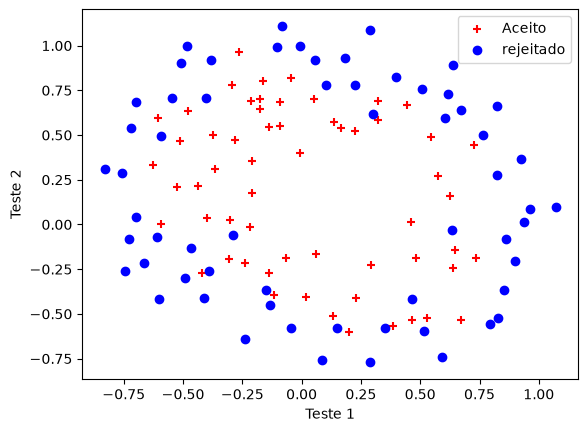

In [30]:
# Encontrando os indíces das amostras positivas e negativas
pos = np.where(y==1)[0]
neg = np.where(y==0)[0]

# Plotando as amostras
plt.scatter(X[pos, 0], X[pos, 1], marker='+', c='red', label='Aceito')
plt.scatter(X[neg, 0], X[neg, 1], marker='o', c='blue', label='rejeitado')
plt.xlabel('Teste 1')
plt.ylabel('Teste 2')
plt.legend()
plt.show()


### 4.2 - Mapeamento de Atributos (Feature Mapping)

Uma forma de obtermos uma curva não linear para os dados originais, utilizando o ferramental de regressão linear, é criando mais features a partir das já existentes. Para isso, implemente a função "map_feature" que recebe a base de dados com as features originais e retorna uma nova base de dados, com o mapeamento das features para todos os termos polinomiais de $x_1$ e $x_2$ até uma potência pré-estabelecida (ex: grau 6).
$$Map\_Features(X)= \begin{bmatrix} 1 \\ x_1 \\ x_2 \\ x_1x_2 \\ x_1^2 \\ x_2^2 \\ x_1^3 \\ \vdots \\ x_1x_2^5 \\ x_2^6 \end{bmatrix}$$

Considerando-se o exemplo com grau 6, cada AMOSTRA de treinamento que correspondia a um vetor de 2 ATRIBUTOS (variáveis), será transformado em um vetor com 28 ATRIBUTOS (features). Desta maneira, o nosso modelo de regressão logística aprendido a partir deste novo vetor de atributos com maior dimensão, terá uma fronteira de decisão de maior complexidade, parecendo não-linear quando plotada no gráfico bidimensional relativo aos atributos originais da base.

Este recurso nos permite construir um classificador mais eficiente para o ajuste de regiões complexas, entretanto, ele também está mais inclinado ao problema de overfitting.

In [31]:
def map_feature(X1, X2, degree):
    X1, X2 = np.broadcast_arrays(np.asarray(X1), np.asarray(X2))
    dataset_novo = np.column_stack([
        (X1 ** (i-j) * X2 ** j).ravel()
        for i in range(degree + 1) for j in range(i + 1)
    ])
    return dataset_novo

X_mapped = map_feature(X[:, 0], X[:, 1], 6)
assert X_mapped.shape == (118, 28)
assert np.allclose(map_feature([2], [3], 2), [[1, 2, 3, 4, 6, 9]])
X_mapped[:5]

array([[ 1.00000000e+00,  5.12670000e-02,  6.99560000e-01,
         2.62830529e-03,  3.58643425e-02,  4.89384194e-01,
         1.34745327e-04,  1.83865725e-03,  2.50892595e-02,
         3.42353606e-01,  6.90798869e-06,  9.42624411e-05,
         1.28625106e-03,  1.75514423e-02,  2.39496889e-01,
         3.54151856e-07,  4.83255257e-06,  6.59422333e-05,
         8.99809795e-04,  1.22782870e-02,  1.67542444e-01,
         1.81563032e-08,  2.47750473e-07,  3.38066048e-06,
         4.61305487e-05,  6.29470940e-04,  8.58939846e-03,
         1.17205992e-01],
       [ 1.00000000e+00, -9.27420000e-02,  6.84940000e-01,
         8.60107856e-03, -6.35227055e-02,  4.69142804e-01,
        -7.97681228e-04,  5.89122275e-03, -4.35092419e-02,
         3.21334672e-01,  7.39785525e-05, -5.46363780e-04,
         4.03513411e-03, -2.98012201e-02,  2.20094970e-01,
        -6.86091891e-06,  5.06708697e-05, -3.74226408e-04,
         2.76382476e-03, -2.04120477e-02,  1.50751849e-01,
         6.36295342e-07, -4.69

### 4.3 - Função de custo e gradiente

Recapitulando. Regularização é realizada a partir da penalização de $\vec{\theta}$, com o objetivo de reduzir a magnitude dos parâmetros. Para isto, adicionamos um termos de regularização $\frac{\lambda}{m}\displaystyle\sum_{j=1}^{n}{\theta_j}^2$ onde $\lambda$ é o parâmetro de regularização. Para obtenção de um modelo de complexidade adequada ao problema que queremos resolver, é necessário encontrar o valor ideal de $\lambda$, uma vez que $\lambda=0$ elimina a regularização enquanto um valor muito grande para $\lambda$ penaliza excessivamente $\vec{\theta}$ gerando um modelo com underfitting. A função de custo para regressão logística com regularização tem a seguinte forma:
$$J(\theta) = \frac{1}{m}\displaystyle\sum_{i=1}^{m}-\begin{bmatrix}y^{(i)}\log h(x^{(i)}+(1-y^{(i)}\log(1-h_\theta(x^{(i)})) \end{bmatrix} + \frac{\lambda}{m}\displaystyle\sum_{j=1}^{n}{\theta_j}^2$$

Obs: Reveja o trecho da aula sobre regularização aplicada à regressão logística.

Implemente a função de custo regularizada:

**Nota da resolução - consistência da regularização:** o custo acima no roteiro usa $\lambda\sum\theta_j^2/m$, enquanto o gradiente fornecido corresponde a $\lambda\sum\theta_j^2/(2m)$. Nesta resolução foi adotada a segunda convenção, cuja derivada é $\lambda\theta_j/m$. O intercepto não é penalizado. Custo e gradiente foram conferidos por diferenças finitas com parâmetros não nulos; os testes com parâmetros nulos também são apresentados.

In [32]:
def compute_regularized_cost(X, y, theta, _lambda):
    theta = np.asarray(theta).ravel()
    regularization = _lambda * np.sum(theta[1:] ** 2) / (2 * len(y))
    cost = compute_cost(theta, X, y)
    return cost + regularization

O gradiente para a função regularizada também é modificado, sendo definido da seguinte forma:

$$\theta_0 = \theta_0 - \alpha \frac{1}{m}\sum_{i=1}^{m} (h_{\theta}(\vec{x}^{(i)}) - y^{(i)})x_0^{(i)}) \qquad j =0\\
\theta_j = \theta_j - \alpha \left[\left(\frac{1}{m}\sum_{i=1}^{m} (h_{\theta}(\vec{x}^{(i)}) - y^{(i)})x_j^{(i)}\right) + \frac{\lambda}{m}\theta_j\right] \qquad j \in \{1, 2, \dots, n\}
$$

Observe que $\theta_0$ não é penalizado, isso costuma ser uma convenção.

Agora, implemente a função "compute_regularized_gradient" e teste com os parâmetros iniciais iguais a zero. Faça testes utilizando diferentes valores para $\lambda$. Ex: $\lambda=0, \lambda=1, \lambda=100$. Para $\lambda=1$ a função de custo deve retornar um valor de aproximadamente $0.693$.

In [33]:
def compute_regularized_gradient(X, y, theta, _lambda):
    theta = np.asarray(theta).ravel()
    grad = compute_gradient(theta, X, y).copy()
    grad[1:] += _lambda * theta[1:] / len(y)
    return grad

In [34]:
initial_theta = np.zeros(X_mapped.shape[1])
for _lambda in [0., 1., 100.]:
    cost = compute_regularized_cost(X_mapped, y, initial_theta, _lambda)
    grad = compute_regularized_gradient(X_mapped, y, initial_theta, _lambda)
    print(f'λ = {_lambda:g}; custo com θ = 0: {cost:.6f}')
    print('Gradiente com θ = 0:', grad)
    assert np.isclose(cost, np.log(2))
    assert np.allclose(grad, X_mapped.T @ (.5 - y) / len(y))
    # Com θ não nulo, verifica-se também a derivada da penalização.
    erro = check_grad(
        lambda t: compute_regularized_cost(X_mapped, y, t, _lambda),
        lambda t: compute_regularized_gradient(X_mapped, y, t, _lambda),
        np.linspace(-.2, .2, X_mapped.shape[1]))
    assert erro < 1e-5

λ = 0; custo com θ = 0: 0.693147
Gradiente com θ = 0: [8.47457627e-03 1.87880932e-02 7.77711864e-05 5.03446395e-02
 1.15013308e-02 3.76648474e-02 1.83559872e-02 7.32393391e-03
 8.19244468e-03 2.34764889e-02 3.93486234e-02 2.23923907e-03
 1.28600503e-02 3.09593720e-03 3.93028171e-02 1.99707467e-02
 4.32983232e-03 3.38643902e-03 5.83822078e-03 4.47629067e-03
 3.10079849e-02 3.10312442e-02 1.09740238e-03 6.31570797e-03
 4.08503006e-04 7.26504316e-03 1.37646175e-03 3.87936363e-02]
λ = 1; custo com θ = 0: 0.693147
Gradiente com θ = 0: [8.47457627e-03 1.87880932e-02 7.77711864e-05 5.03446395e-02
 1.15013308e-02 3.76648474e-02 1.83559872e-02 7.32393391e-03
 8.19244468e-03 2.34764889e-02 3.93486234e-02 2.23923907e-03
 1.28600503e-02 3.09593720e-03 3.93028171e-02 1.99707467e-02
 4.32983232e-03 3.38643902e-03 5.83822078e-03 4.47629067e-03
 3.10079849e-02 3.10312442e-02 1.09740238e-03 6.31570797e-03
 4.08503006e-04 7.26504316e-03 1.37646175e-03 3.87936363e-02]
λ = 100; custo com θ = 0: 0.693147
G

Utilizando as funções que você criou (compute_regularized_cost e compute_regularized_gradient) utilize a função minimize do pacote scipy.optimize para encontrar os valores ótimos de $\vec{\theta}$.

OBS: Caso você tenha dificuldades de utilizar a função minimize do pacote scipy.optimize, pode-se utilizar o Gradiente Descendente, de maneira similar à implementação feita nas primeiras seções deste trabalho.

In [35]:
from scipy.optimize import minimize

def fit_regularized(X, y, _lambda):
    result = minimize(
        lambda theta: compute_regularized_cost(X, y, theta, _lambda),
        np.zeros(X.shape[1]),
        jac=lambda theta: compute_regularized_gradient(X, y, theta, _lambda),
        method='BFGS', options={'maxiter': 5000, 'gtol': 1e-7})
    assert result.success, result.message
    return result

_lambda = 1.
result = fit_regularized(X_mapped, y, _lambda)
theta = result.x
print('Convergência:', result.message)
print(f'Acurácia na base completa: {accuracy(X_mapped, y, theta):.2%}')

Convergência: Optimization terminated successfully.
Acurácia na base completa: 83.05%


### 4.4 - Visualizando a Fronteira de Decisão

Aqui, você deve plotar a superfície de decisão. Procure informações a respeito da função "contour" para ter auxílio na plotagem da superfície.

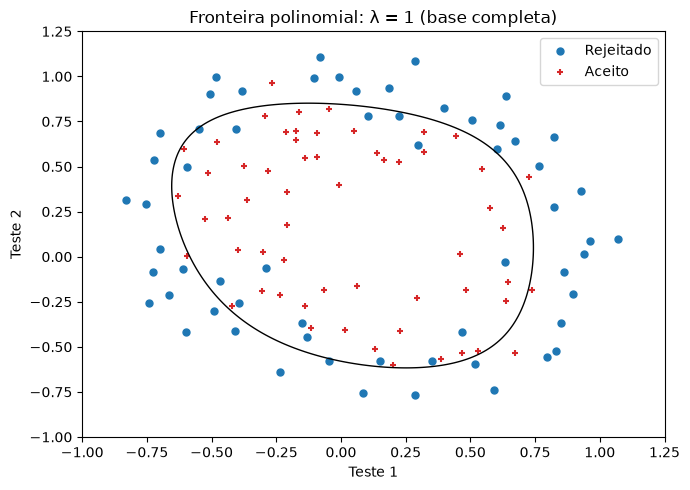

In [36]:
def plot_boundary(ax, theta, X, y, title):
    for classe, marcador, cor, rotulo in [(0, 'o', 'tab:blue', 'Rejeitado'),
                                         (1, '+', 'tab:red', 'Aceito')]:
        mask = y == classe
        ax.scatter(X[mask, 0], X[mask, 1], marker=marcador, c=cor, label=rotulo, s=25)
    u, v = np.meshgrid(np.linspace(-1, 1.25, 220), np.linspace(-1, 1.25, 220))
    z = (map_feature(u, v, 6) @ theta).reshape(u.shape)
    if z.min() <= 0 <= z.max():
        ax.contour(u, v, z, levels=[0], colors=['black'], linewidths=1)
    else:
        ax.text(.02, .02, 'Sem cruzamento p = 0,5 na grade', transform=ax.transAxes, fontsize=7)
    ax.set(xlabel='Teste 1', ylabel='Teste 2', title=title,
           xlim=(-1, 1.25), ylim=(-1, 1.25))

fig, ax = plt.subplots(figsize=(7, 5))
plot_boundary(ax, theta, X, y, 'Fronteira polinomial: λ = 1 (base completa)')
ax.legend()
plt.tight_layout()
plt.show()

A sua implementação deve plotar um gráfico semelhante ao apresentado a seguir:

**Nota sobre o material original:** o arquivo de referência `fig_logistic_regularization.png` não acompanhou os materiais disponíveis. O gráfico produzido na célula anterior apresenta a fronteira obtida nesta resolução; não substitui nem reproduz a imagem de referência do professor.

Agora que já é possível visualizar uma fronteira de separação para o problema, divida os dados em 2 partes (treinamento e teste) e realize o treinamento mais 10 vezes, alterando o valor de $\lambda$ e plotando a fronteira de decisão obtida a cada valor testado. Aponte situações onde ocorrem underfitting e overfitting, além de mostrar qual valor de $\lambda$ proporcionou o resultado com maior acurácia para os dados de teste. Lembre-se, o seu modelo será obtido através da aplicação do algoritmo de aprendizado apenas aos dados de treinamento. Os dados de teste serão utilizados apenas para verificar o desempenho do modelo obtido para um determinado valor de $\lambda$.

Obs: Reveja a aula sobre overfitting, regularização e seleção de modelos, onde é mostrado como a validação cruzada pode ser utilizada para se encontrar o melhor valor de $\lambda$.

**Nota da resolução - avaliação:** os dez ajustes usam a mesma divisão estratificada, com 82 observações de treino e 36 de teste, semente 42. O roteiro solicita comparar os valores de λ pelo teste; essa comparação é apresentada como exploratória, pois o teste passa a participar da seleção. O mapeamento polinomial não estima estatísticas dos dados. Os atributos mantêm a escala original, próxima da unidade.

,lambda,acuracia_treino,acuracia_teste,logloss_treino,logloss_teste,norma_pesos,iteracoes,convergiu
0,0.0001,0.926829,0.833333,0.165566,1.840150,174.742091,337,True
1,0.0010,0.890244,0.833333,0.208892,0.884741,56.385384,240,True
2,0.0100,0.853659,0.833333,0.251651,0.538071,22.414794,173,True
3,0.1000,0.829268,0.805556,0.324339,0.437315,9.821683,105,True
4,0.3000,0.829268,0.805556,0.384477,0.459054,6.203777,83,True
5,1.0000,0.829268,0.777778,0.472107,0.523610,3.345363,60,True
6,3.0000,0.817073,0.666667,0.555919,0.591325,1.664677,41,True
7,10.0000,0.768293,0.611111,0.625334,0.645391,0.684345,25,True
8,100.0000,0.536585,0.500000,0.682286,0.686217,0.091799,8,True
9,1000.0000,0.512195,0.500000,0.691712,0.692671,0.009644,13,True


Treino: 82; teste: 36
Maior acurácia no teste: 83.33%; λ empatados: [0.0001, 0.001, 0.01]


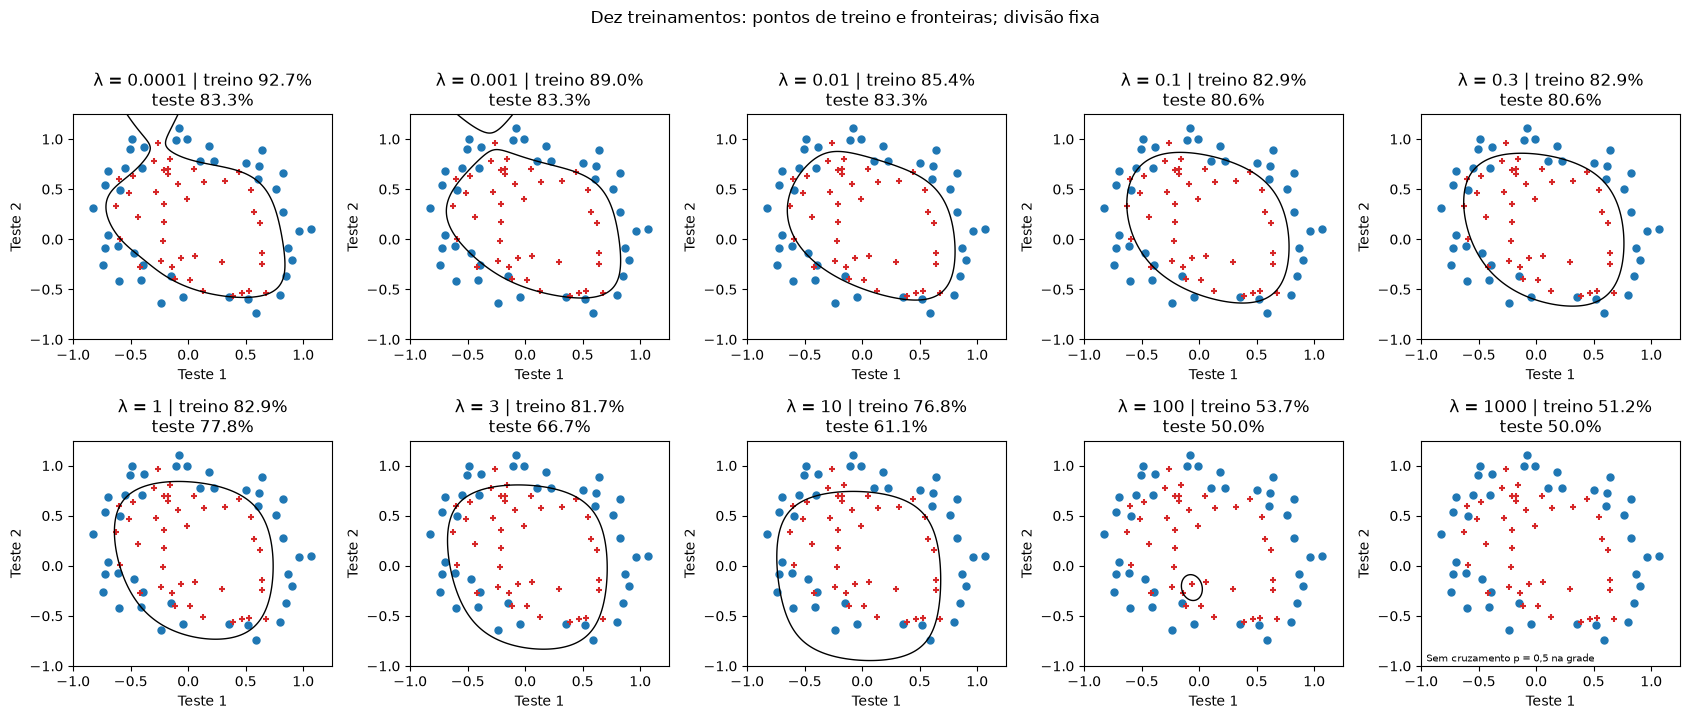

In [37]:
from sklearn.model_selection import train_test_split

SEED = 42
indices_train, indices_test = train_test_split(
    np.arange(len(y)), test_size=.3, stratify=y, random_state=SEED)
X_train, X_test = X_mapped[indices_train], X_mapped[indices_test]
y_train, y_test = y[indices_train], y[indices_test]
assert set(indices_train).isdisjoint(indices_test)
assert len(indices_train) + len(indices_test) == len(y)
lambdas = np.array([.0001, .001, .01, .1, .3, 1., 3., 10., 100., 1000.])
results, models = [], []
for _lambda in lambdas:
    result = fit_regularized(X_train, y_train, _lambda)
    models.append(result)
    results.append({
        'lambda': _lambda,
        'acuracia_treino': accuracy(X_train, y_train, result.x),
        'acuracia_teste': accuracy(X_test, y_test, result.x),
        'logloss_treino': compute_cost(result.x, X_train, y_train),
        'logloss_teste': compute_cost(result.x, X_test, y_test),
        'norma_pesos': np.linalg.norm(result.x[1:]),
        'iteracoes': result.nit, 'convergiu': bool(result.success)})
results = pd.DataFrame(results)
display(results)
print(f'Treino: {len(y_train)}; teste: {len(y_test)}')
best_accuracy = results.acuracia_teste.max()
best_lambdas = results.loc[np.isclose(results.acuracia_teste, best_accuracy), 'lambda'].tolist()
print(f'Maior acurácia no teste: {best_accuracy:.2%}; λ empatados: {best_lambdas}')
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, _lambda, model, row in zip(axes.ravel(), lambdas, models, results.to_dict('records')):
    plot_boundary(ax, model.x, X[indices_train], y_train,
        f'λ = {_lambda:g} | treino {row["acuracia_treino"]:.1%}\nteste {row["acuracia_teste"]:.1%}')
fig.suptitle('Dez treinamentos: pontos de treino e fronteiras; divisão fixa', y=1.02)
plt.tight_layout()
plt.show()
assert len(models) == 10
assert np.isclose(best_accuracy, 30/36)

In [38]:
# Complemento à observação do roteiro: validação cruzada apenas no treino.
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = []
for _lambda in lambdas:
    scores = []
    for train_fold, validation_fold in cv.split(X_train, y_train):
        model = fit_regularized(X_train[train_fold], y_train[train_fold], _lambda)
        scores.append(accuracy(X_train[validation_fold], y_train[validation_fold], model.x))
    cv_results.append({'lambda': _lambda, 'acuracia_media': np.mean(scores),
                       'desvio_padrao': np.std(scores, ddof=1)})
cv_results = pd.DataFrame(cv_results)
display(cv_results)
# Maior média; em empate numérico, maior lambda.
lambda_cv = cv_results.loc[np.isclose(cv_results.acuracia_media,
                                    cv_results.acuracia_media.max()), 'lambda'].max()
print(f'λ selecionado pela validação cruzada no treino: {lambda_cv:g}')
assert np.isclose(lambda_cv, .3)

,lambda,acuracia_media,desvio_padrao
0,0.0001,0.769853,0.058397
1,0.0010,0.805147,0.023106
2,0.0100,0.793382,0.051365
3,0.1000,0.794853,0.094750
4,0.3000,0.806618,0.072957
5,1.0000,0.769118,0.077092
6,3.0000,0.782353,0.074325
7,10.0000,0.698529,0.157209
8,100.0000,0.558824,0.080547
9,1000.0000,0.511765,0.016109


λ selecionado pela validação cruzada no treino: 0.3


O gráfico a seguir foi obtido utilizando-se $\lambda = 0.0001$:

**Nota sobre o material original:** o arquivo de referência `fig_logistic_regularization_overfitting.png` não acompanhou os materiais disponíveis. A fronteira correspondente a λ = 0,0001 está no primeiro painel dos dez experimentos executados acima.

**Análise da resolução:** λ = 0,0001, 0,001 e 0,01 empataram em 83,33% no teste. Em λ = 0,0001, foram obtidos 92,68% no treino, norma de pesos 174,74 e perdas logísticas de 0,166 no treino e 1,840 no teste. A fronteira mais complexa e a pior perda fora do treino são compatíveis com overfitting, embora uma única divisão não prove esse diagnóstico. Para λ = 0,01, a perda no teste foi 0,538, apesar da mesma acurácia.

Com λ = 1000, a acurácia caiu para 51,22% no treino e 50,00% no teste, comportamento compatível com underfitting. A validação cruzada no treino selecionou λ = 0,3, com média 80,66%, muito próxima dos 80,51% de λ = 0,001. Essa diferença não demonstra superioridade robusta. Cada observação representa 2,78 pontos percentuais na acurácia do teste; diferenças pequenas exigem cautela. A validação cruzada complementar não recupera a independência do teste já consultado.

## 5 - O que deve ser entregue

Você deve entregar através do sistema, este notebook totalmente preenchido com o que se pede em cada item onde uma implementação é necessária. Caso esteja utilizando algum código ou imagem anexado ao notebook, envie junto, em um arquivo .zip.

Adicionalmente, faça um relatório de 1 a 3 páginas(anexe ao .zip) para apresentar suas análises e conclusões sobre as diversas seções deste trabalho.

**Nota da resolução - organização da entrega:** notebook preenchido, relatório e quatro datasets estão reunidos no repositório indicado em `submission.md`. O relatório está em `report.md`.

## 6 - Créditos

Este trabalho é uma tradução/adaptação de parte dos trabalhos práticos do curso Stanford CS229 - Machine Learning, de autoria do prof. Andrew Ng.

**Autoria da resolução:** implementações, experimentos e análises de Angelina de Meiras Ottoni, com apoio de IA na preparação e verificação. Os enunciados e os créditos originais foram preservados. Slides e demais materiais de aula não integram a resolução publicada. Os quatro datasets são os fornecidos para o exercício, sem atribuição de autoria à estudante.